<a href="https://colab.research.google.com/github/Luppouk/Atividades-Calculo-Numerico/blob/main/Atividade_1910/atividade.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lista de Exercícios - Método de Gauss–Seidel

Sistema:
$$
\begin{cases}
10x - y + 2z = 6 \\
-x + 11y - z = 22 \\
2x - y + 10z = -10
\end{cases}
$$


## Questão 5 - Implementação do método de Gauss–Seidel

Em cada equação, isola-se a incógnita da diagonal: $x_i = \dfrac{b_i - \sum_{j \neq i} a_{ij} x_j}{a_{ii}}$. O vetor `x` é atualizado no lugar, então cada incógnita já usa os valores novos calculados na mesma iteração. É isso que caracteriza o Gauss–Seidel. A cada iteração calcula-se o erro $\max_i |x_i^{(k)} - x_i^{(k-1)}|$, e o laço para quando ele fica menor que $10^{-5}$. Aproximação inicial: $x^{(0)} = (0, 0, 0)$.

In [ ]:
import numpy as np

# Sistema Ax = b
A = np.array([[10, -1,  2],
              [-1, 11, -1],
              [ 2, -1, 10]], dtype=float)
b = np.array([6, 22, -10], dtype=float)

def gauss_seidel(A, b, x0, tol=1e-5, max_iter=100):
    n = len(b)
    x = np.array(x0, dtype=float)
    historico = [x.copy()]   # guarda x(0), x(1), x(2), ...
    erros = [np.nan]         # x(0) não tem erro
    for k in range(1, max_iter + 1):
        x_ant = x.copy()
        for i in range(n):
            # x é atualizado no lugar: para j < i, x[j] já é o valor NOVO
            # (iteração k); para j > i, ainda é o valor ANTIGO (k-1).
            soma = sum(A[i, j] * x[j] for j in range(n) if j != i)
            x[i] = (b[i] - soma) / A[i, i]
        erro = np.max(np.abs(x - x_ant))   # norma infinito
        historico.append(x.copy())
        erros.append(erro)
        if erro < tol:                     # critério de parada
            return x, k, np.array(historico), np.array(erros)
    print("Atenção: não convergiu em", max_iter, "iterações")
    return x, max_iter, np.array(historico), np.array(erros)

In [ ]:
x_sol, n_iter, hist, erros = gauss_seidel(A, b, x0=[0, 0, 0], tol=1e-5)

print(f"Número de iterações: {n_iter}")
print(f"Solução aproximada: x = {x_sol[0]:.6f}, y = {x_sol[1]:.6f}, z = {x_sol[2]:.6f}")
print("Conferência (numpy.linalg.solve):", np.linalg.solve(A, b))

Número de iterações: 6
Solução aproximada: x = 1.000000, y = 2.000000, z = -1.000000
Conferência (numpy.linalg.solve): [ 1.  2. -1.]


## Questão 6 - Tabela das iterações

A função guarda o vetor de cada iteração (`hist`) e o erro correspondente (`erros`). Aqui eles são organizados em um `DataFrame` do pandas. Em $k = 0$ não há erro, pois não existe iteração anterior.

In [ ]:
import pandas as pd

tabela = pd.DataFrame({
    "k": range(len(hist)),
    "x(k)": hist[:, 0],
    "y(k)": hist[:, 1],
    "z(k)": hist[:, 2],
    "||x(k) - x(k-1)||∞": erros,
})

tabela.style.format({"x(k)": "{:.8f}", "y(k)": "{:.8f}", "z(k)": "{:.8f}",
                     "||x(k) - x(k-1)||∞": "{:.4e}"}, na_rep="—").hide(axis="index")

k,x(k),y(k),z(k),||x(k) - x(k-1)||∞
0,0.00000000,0.00000000,0.00000000,—
1,0.60000000,2.05454545,-0.91454545,2.0545e+00
2,0.98836364,2.00671074,-0.99700165,3.8836e-01
3,1.00007140,2.00027907,-0.99998637,1.1708e-02
4,1.00002518,2.00000353,-1.00000468,2.7554e-04
5,1.00000129,1.99999969,-1.00000029,2.3892e-05
6,1.00000003,1.99999998,-1.00000001,1.2626e-06


## Questão 7 — Gráficos

**a)** $x^{(k)}$, $y^{(k)}$ e $z^{(k)}$ em função da iteração $k$, no mesmo gráfico. As linhas tracejadas cinza marcam a solução exata (1, 2 e −1) como referência.

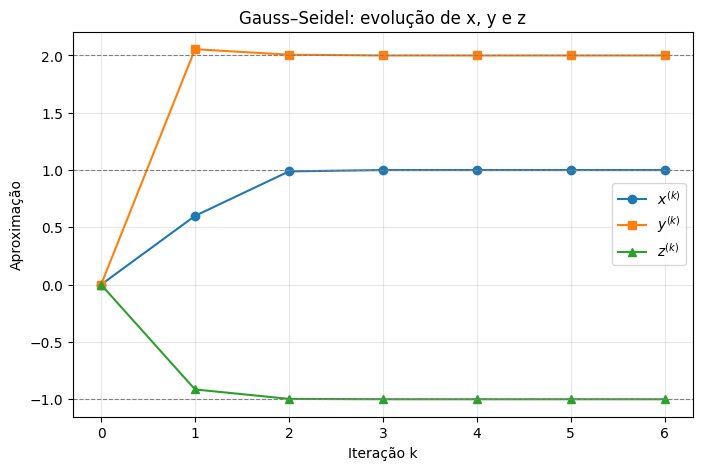

In [ ]:
import matplotlib.pyplot as plt

k = np.arange(len(hist))
plt.figure(figsize=(8, 5))
plt.plot(k, hist[:, 0], "o-", label=r"$x^{(k)}$")
plt.plot(k, hist[:, 1], "s-", label=r"$y^{(k)}$")
plt.plot(k, hist[:, 2], "^-", label=r"$z^{(k)}$")
for valor in [1, 2, -1]:  # solução exata, para referência
    plt.axhline(valor, color="gray", linestyle="--", linewidth=0.8)
plt.xlabel("Iteração k")
plt.ylabel("Aproximação")
plt.title("Gauss–Seidel: evolução de x, y e z")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

**b)** Erro entre iterações $\|x^{(k)} - x^{(k-1)}\|_\infty$ em função de $k$, com o eixo vertical em escala logarítmica. A linha vermelha marca a tolerância $10^{-5}$. O gráfico começa em $k = 1$ porque $k = 0$ não tem erro.

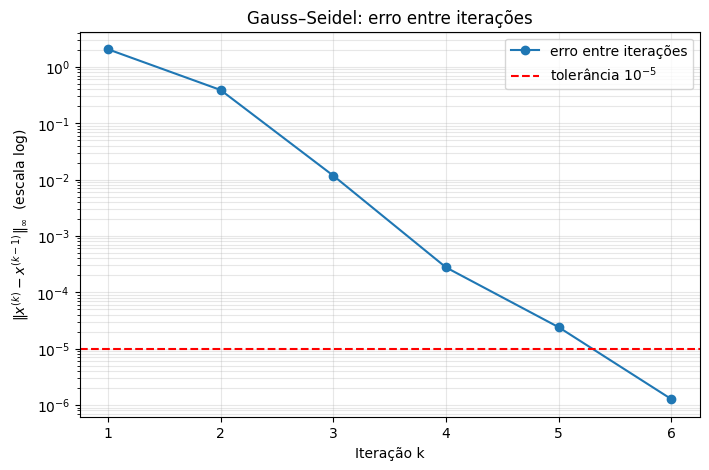

In [ ]:
plt.figure(figsize=(8, 5))
plt.semilogy(k[1:], erros[1:], "o-", label="erro entre iterações")
plt.axhline(1e-5, color="red", linestyle="--", label=r"tolerância $10^{-5}$")
plt.xlabel("Iteração k")
plt.ylabel(r"$\Vert x^{(k)} - x^{(k-1)} \Vert_\infty$  (escala log)")
plt.title("Gauss–Seidel: erro entre iterações")
plt.legend()
plt.grid(True, which="both", alpha=0.3)
plt.show()